# 22. A daily M4 project: guarded selection, resume and cost

**Goal and requirements.** Run a small forecasting project on real daily M4 series, from drawing the sample to the evaluation: prepare the temporal validation, compare AutoHybTS's guarded selection with choosing the lowest error, log each series to an SQLite database (which lets an interrupted project resume without redoing what finished) and measure the cost. The project uses only the **official training data**: its last 14 points are sealed for the internal evaluation, and the official test is not downloaded. `stats` and `plot` extras; the first run downloads the daily M4 training data.

In [1]:
import shutil
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment, ExperimentStore
from autohybts.benchmarks import benchmark_cases

warnings.filterwarnings("ignore")
print("AutoHybTS", autohybts.__version__)

AutoHybTS 1.0.0rc4


## 1. Data and protocol

The sample is 3 series drawn with seed 0 out of the 4227 daily M4 series; nobody picks them by hand. Of each we use only the official training data, cut to the last 730 days to control the cost. The horizon is daily M4's, 14 steps, forecast at once (protocol A); the MASE scaling period is M4's (1).

In [2]:
cases = list(benchmark_cases("m4", "daily", 3, 0, development_only=True, development_tail=730))
H = cases[0].horizon
pd.DataFrame(
    [
        {
            "series": case.series_id,
            "official_train": case.source["original_train_length"],
            "points_used": len(case.values),
            "start": case.values.index[0].date(),
            "end": case.values.index[-1].date(),
        }
        for case in cases
    ]
).set_index("series")

,official_train,points_used,start,end
series,,,,
D2692,4197,730,2010-09-26,2012-09-24
D2161,172,172,2002-12-23,2003-06-12
D3594,4197,730,2010-09-26,2012-09-24


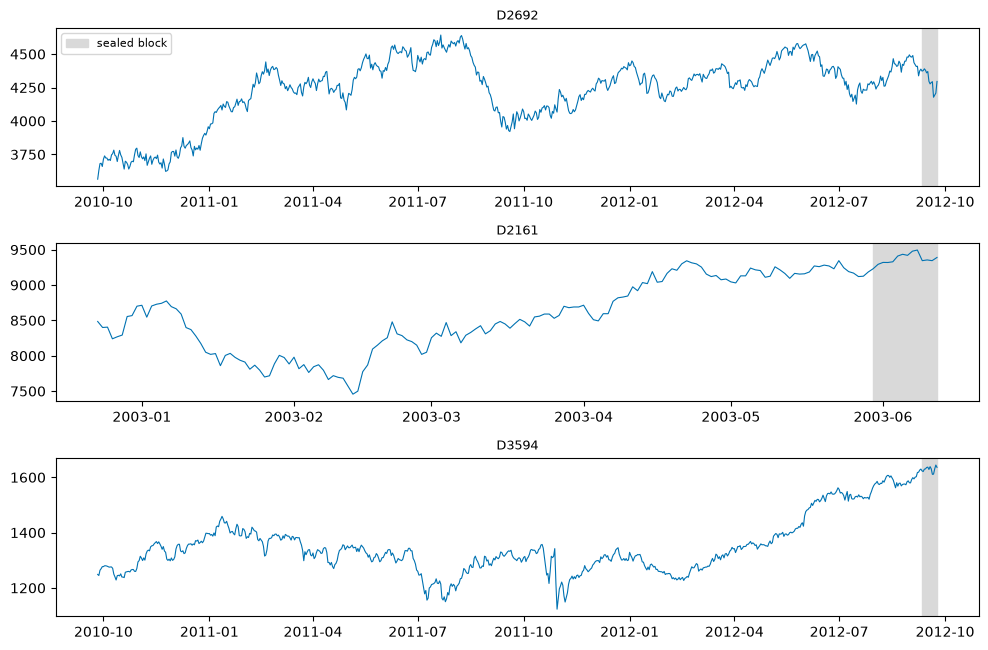

In [3]:
fig, axes = plt.subplots(len(cases), 1, figsize=(10, 2.2 * len(cases)))
for ax, case in zip(axes, cases, strict=True):
    ax.plot(case.values.index, case.values.to_numpy(), linewidth=0.8, color="#0072B2")
    ax.axvspan(case.values.index[-H], case.values.index[-1], color="0.85", label="sealed block")
    ax.set_title(case.series_id, fontsize=9)
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Causal exploration

`fit` searches nothing: it validates the series, seals the last 14 points and fixes the `V_search` and `V_select` origins. The table shows how many origins each series allows per layer (the acceptance rule was calibrated with 7) and how many differences ADF and KPSS together ask for on the development stretch.

In [4]:
SETTINGS = {
    "fh": H,
    "seasonal_period": cases[0].seasonal_period,
    "session_id": 42,
    "budget": "small",
    "base_models": ["naive", "random_walk_drift", "linear", "exponential_smoothing"],
    "correctors": ["linear", "knn"],
}
experiments = {case.series_id: AutoHybridExperiment(**SETTINGS).fit(case.values) for case in cases}
pd.DataFrame(
    {
        sid: {
            "development_points": len(exp.history_),
            "origins_per_layer": exp.fold_,
            "suggested_differences": int(exp.stationarity_report()["d_consensus"].iloc[0]),
        }
        for sid, exp in experiments.items()
    }
).T

,development_points,origins_per_layer,suggested_differences
D2692,716,7,1
D2161,158,4,1
D3594,716,7,1


## 3. Controls and proposed models

The same search (persistence, random walk with drift, linear regression, exponential smoothing and linear and KNN residual corrections) feeds three choices:

- **guarded selection** (`compare_models().best`): accepts complexity only when it passes the acceptance rule;
- **lowest error**: the finalist with the lowest MASE on `V_select`, without a threshold;
- **persistence**: the simplest control.

Each series becomes a run in the database `artifacts/m4_project/m4.db`, deleted at the start so the run is reproducible.

In [5]:
folder = Path("artifacts/m4_project")
shutil.rmtree(folder, ignore_errors=True)
store = ExperimentStore(folder / "m4.db")
results, seconds = {}, {}


def run_project():
    """Search every series not yet in the database; a finished series is never redone."""
    done = set(store.runs().name) if (folder / "m4.db").exists() else set()
    new = []
    for sid, exp in experiments.items():
        if sid in done:
            continue
        started = time.perf_counter()
        results[sid] = exp.compare_models()
        seconds[sid] = time.perf_counter() - started
        store.log(exp, name=sid, tags={"project": "m4-daily"})
        new.append(sid)
    return new

## 4. Search and selection

The first call searches the three series. The second simulates resuming an interrupted project: the database already has the three runs, so nothing is redone.

In [6]:
print("first call:", run_project())
print("resume:", run_project())
pd.Series(seconds, name="seconds").round(1)

first call: ['D2692', 'D2161', 'D3594']
resume: []


D2692    11.5
D2161     1.4
D3594    10.7
Name: seconds, dtype: float64

## 5. Results and plots

The database answers who won in each series and why: each challenger compared with the current champion, with median gain, win rate and reason.

In [7]:
store.query(
    """
    SELECT r.name AS series, d.family, d.challenger_label AS challenger, d.accepted AS accepted,
           ROUND(d.median_gain, 3) AS median_gain, ROUND(d.win_rate, 2) AS win_rate,
           d.reason_codes AS reasons
    FROM decisions d JOIN runs r USING (run_id)
    ORDER BY r.name, d.step
    """
)

,series,family,challenger,accepted,median_gain,win_rate,reasons
0,D2161,linear,linear(lags=7),0,-0.639,0.00,"[""median_gain_below_threshold"", ""win_rate_belo..."
1,D2161,residual,"naive + linear [w=7, alpha=0.5, historical_oof...",0,0.037,1.00,"[""median_gain_below_threshold""]"
2,D2692,linear,linear(lags=7),0,0.064,0.57,"[""win_rate_below_threshold""]"
3,D2692,residual,"random_walk_drift + linear [w=7, alpha=0.5, hi...",0,-0.008,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
4,D3594,linear,linear(lags=7),0,-0.184,0.29,"[""median_gain_below_threshold"", ""win_rate_belo..."
5,D3594,residual,"random_walk_drift + linear [w=7, alpha=1.0, hi...",0,-0.002,0.43,"[""median_gain_below_threshold"", ""win_rate_belo..."


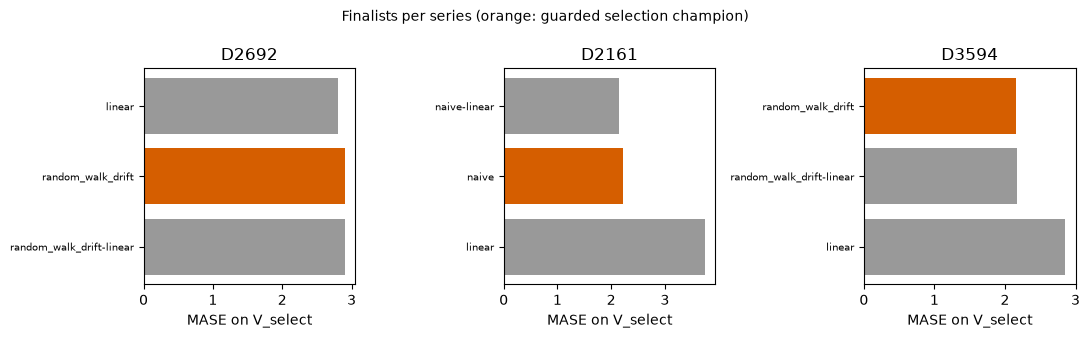

In [8]:
choices = {}
for sid, result in results.items():
    board = result.selection_leaderboard.sort_values("MASE")
    lowest = next(
        r.candidate for r in result.selection.finalists if r.candidate_id == board.index[0]
    )
    choices[sid] = {"guarded": result.best, "lowest error": lowest}

fig, axes = plt.subplots(1, len(results), figsize=(11, 3.4), sharey=False)
for ax, (sid, result) in zip(axes, results.items(), strict=True):
    board = result.selection_leaderboard.sort_values("MASE")
    colors = ["#D55E00" if champion else "0.6" for champion in board.is_champion]
    ax.barh(board.name, board.MASE, color=colors)
    ax.invert_yaxis()
    ax.set(title=sid, xlabel="MASE on V_select")
    ax.tick_params(axis="y", labelsize=7)
fig.suptitle("Finalists per series (orange: guarded selection champion)", fontsize=10)
fig.tight_layout()
plt.show()

## 6. Diagnostics and limits

A short series allows fewer origins than the acceptance rule's calibrated 7; with fewer units the rule accepts spurious structures more often, and the experiment warns. Three series, one seed and the `small` budget size the project, but do not support conclusions about the whole M4.

In [9]:
store.query(
    """
    SELECT r.name AS series, r.n_origins AS origins_both_layers, COUNT(l.seq) AS proposals,
           SUM(l.status = 'EVALUATED') AS evaluated, ROUND(SUM(l.seconds), 1) AS search_seconds
    FROM runs r JOIN ledger l USING (run_id)
    GROUP BY r.name ORDER BY r.name
    """
)

,series,origins_both_layers,proposals,evaluated,search_seconds
0,D2161,8,32,17,1.3
1,D2692,14,32,17,11.1
2,D3594,14,32,17,10.3


## 7. Internal evaluation and cost

Each choice is refitted on the development history and read a single time on the sealed 14-day block. When the guarded selection and the lowest error choose the same candidate, it is read only once.

In [10]:
rows, paths = [], {}
for sid, exp in experiments.items():
    picks = {**choices[sid], "persistence": exp.create_model("naive").candidate}
    read = {}
    for label, spec in picks.items():
        if spec.candidate_id not in read:
            read[spec.candidate_id] = exp.evaluate_external(exp.finalize_model(spec))
        external = read[spec.candidate_id]
        rows.append(
            {
                "series": sid,
                "choice": label,
                "model": spec.label,
                "MASE": external.metrics["MASE"].iloc[0],
            }
        )
        paths[sid, label] = external.predictions
internal = pd.DataFrame(rows)
internal.pivot(index="series", columns="choice", values="MASE").round(3)

choice,guarded,lowest error,persistence
series,,,
D2161,2.591,2.509,2.591
D2692,3.366,2.724,3.058
D3594,0.836,0.836,0.791


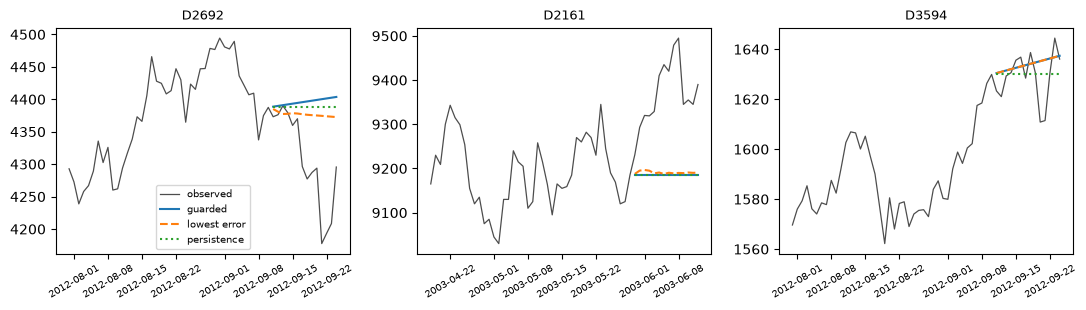

In [11]:
fig, axes = plt.subplots(1, len(cases), figsize=(11, 3.2))
for ax, case in zip(axes, cases, strict=True):
    sid = case.series_id
    recent = case.values.iloc[-4 * H :]
    ax.plot(recent.index, recent.to_numpy(), color="0.3", linewidth=0.9, label="observed")
    for label, style in (("guarded", "-"), ("lowest error", "--"), ("persistence", ":")):
        table = paths[sid, label]
        ax.plot(table.index, table["y_pred"], linestyle=style, label=label)
    ax.set_title(sid, fontsize=9)
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
axes[0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 8. Reading

- **Data.** The draw brought D2692, D2161 and D3594. D2161 has only 172 days of official training data: it allows 4 origins per layer, fewer than the calibrated 7, and the experiment warned. In all three series, ADF and KPSS ask for one difference.
- **Guarded selection.** It kept a standalone model in all three: persistence in D2161 and random walk with drift in the other two. No challenger passed the acceptance rule, for different reasons. In D2161, the persistence + linear corrector hybrid won on all 4 units, but with a median gain of 3.7 %, below 5 %. In D2692, linear regression had a 6.4 % gain but only 57 % wins, below 60 %.
- **Lowest error.** It would choose that hybrid in D2161 and linear regression in D2692. On the sealed 14-day block, those choices had a lower MASE than the guarded selection: 2.51 against 2.59 and 2.72 against 3.37. In D3594 both chose the same model, and persistence was the best (0.79 against 0.84).
- **How to read this.** On this sample, the rule's caution did not pay off: the candidates it refused were close to the threshold and did well on the internal block. But each series had a single 14-day window, and three series do not support a comparison. The rule was calibrated to rarely err by excess complexity over many series, not to win on each one. A study with more series and seeds is what decides whether it is too conservative on daily M4.
- **Resume and cost.** The search took about 22 s over the three series (17 candidates evaluated per series, out of 32 proposals). The second call redid none, because the database already had the three runs: the same mechanism resumes a larger project interrupted midway.